# No-Churn Telecom: Customer Churn Prediction
**Project ID:** PRCL-0017 | **Category:** Telecom, Churn Rate ML

**Project goals**
1. Understand the variables that influence customers to leave
2. Create churn risk scores to drive retention campaigns
3. Create a CHURN-FLAG (YES = 1, NO = 0) to target email campaigns

# Setup and data loading

Import the libraries and load the telecom data from the database, so the analysis starts from the original data.

## Import libraries

In [1]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import quote_plus
from sqlalchemy import create_engine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, roc_curve


warnings.filterwarnings("ignore")

### Connect to database

In [2]:
host = "18.136.157.135"
user = "dm_team3"
password = quote_plus("your_password") # special characters need encoding
db = "project_telecom"

engine = create_engine(f"mysql+pymysql://{user}:{password}@{host}/{db}")

### Load the data

In [3]:
df = pd.read_sql("SELECT * FROM telecom_churn_data", engine)

In [4]:
print(df.shape)
df.head()

(243553, 14)


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


### Observations
- The dataset has 243,553 rows and 14 columns.
- The columns differ from the PDF meta info (there is no Phone column, for example).
- The target column `churn` is already numeric (0 and 1).
- `data_used` has a negative value in row 1 (-361), which needs a check in the cleaning phase.
- `date_of_registration` is a date and needs conversion later.

# Data Understanding

Check the size, data types, summary statistics and churn ratio, to know what the data looks like before changing anything.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 243553 entries, 0 to 243552
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   customer_id           243553 non-null  int64
 1   telecom_partner       243553 non-null  str  
 2   gender                243553 non-null  str  
 3   age                   243553 non-null  int64
 4   state                 243553 non-null  str  
 5   city                  243553 non-null  str  
 6   pincode               243553 non-null  int64
 7   date_of_registration  243553 non-null  str  
 8   num_dependents        243553 non-null  int64
 9   estimated_salary      243553 non-null  int64
 10  calls_made            243553 non-null  int64
 11  sms_sent              243553 non-null  int64
 12  data_used             243553 non-null  int64
 13  churn                 243553 non-null  int64
dtypes: int64(9), str(5)
memory usage: 34.1 MB


In [6]:
df.describe()

,customer_id,age,pincode,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
count,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000
mean,121777.000000,46.077609,549501.270541,1.997500,85021.137839,49.010548,23.945404,4993.186025,0.200478
std,70307.839393,16.444029,259808.860574,1.414941,37508.963233,29.453556,14.733575,2942.019547,0.400359
min,1.000000,18.000000,100006.000000,0.000000,20000.000000,-10.000000,-5.000000,-987.000000,0.000000
25%,60889.000000,32.000000,324586.000000,1.000000,52585.000000,24.000000,11.000000,2490.000000,0.000000
50%,121777.000000,46.000000,548112.000000,2.000000,84990.000000,49.000000,24.000000,4987.000000,0.000000
75%,182665.000000,60.000000,774994.000000,3.000000,117488.000000,74.000000,36.000000,7493.000000,0.000000
max,243553.000000,74.000000,999987.000000,4.000000,149999.000000,108.000000,53.000000,10991.000000,1.000000


### Churn Distribution

In [7]:
# Count and percentage of each class
print(df["churn"].value_counts())
print(df["churn"].value_counts(normalize=True) * 100)

churn
0    194726
1     48827
Name: count, dtype: int64
churn
0    79.952208
1    20.047792
Name: proportion, dtype: float64


### Unique values in categorical columns

In [8]:
for col in ["telecom_partner", "gender", "state", "city"]:
    print(col, df[col].nunique(), df[col].unique()[:10])

telecom_partner 4 <ArrowStringArray>
['Reliance Jio', 'Vodafone', 'BSNL', 'Airtel']
Length: 4, dtype: str
gender 2 <ArrowStringArray>
['F', 'M']
Length: 2, dtype: str
state 28 <ArrowStringArray>
[        'Karnataka',           'Mizoram', 'Arunachal Pradesh',
        'Tamil Nadu',           'Tripura',       'Uttarakhand',
  'Himachal Pradesh',         'Rajasthan',            'Odisha',
     'Uttar Pradesh']
Length: 10, dtype: str
city 6 <ArrowStringArray>
['Kolkata', 'Mumbai', 'Delhi', 'Chennai', 'Hyderabad', 'Bangalore']
Length: 6, dtype: str


### Observations
- The dataset has 243,553 rows and 14 columns, with no null values.
- `date_of_registration` is stored as text and needs conversion to a date.
- `calls_made` (min -10), `sms_sent` (min -5) and `data_used` (min -987) have negative values, which are invalid and need cleaning.
- `customer_id` and `pincode` are identifiers and will not help the model.
- Churn is imbalanced: 79.95% stayed and 20.05% left, which is above the 10% in the business case. Recall, F1 and ROC-AUC will be used instead of accuracy alone.
- Categorical columns: `telecom_partner` (4), `gender` (2), `state` (28) and `city` (6). They need encoding later.

# Data Cleaning

Fix the invalid values and remove columns that carry no information, so the models learn from clean data.

In [9]:
# duplicates and null values
print(df.duplicated().sum())
print(df.isnull().sum())

0
customer_id             0
telecom_partner         0
gender                  0
age                     0
state                   0
city                    0
pincode                 0
date_of_registration    0
num_dependents          0
estimated_salary        0
calls_made              0
sms_sent                0
data_used               0
churn                   0
dtype: int64


In [10]:
# Convert registration date
df["date_of_registration"] = pd.to_datetime(df["date_of_registration"])

In [11]:
# Check negative values
cols = ["calls_made", "sms_sent", "data_used"]
print((df[cols] < 0).sum())

calls_made    6713
sms_sent      7375
data_used     6050
dtype: int64


In [12]:
# Fixing negative values
# Negative values replaced with the median of valid values
for col in cols:
    median = df.loc[df[col] >= 0, col].median()
    df.loc[df[col] < 0, col] = median

In [13]:
# Drop pincode
# customer_id is kept for the final CHURN-FLAG file
df = df.drop(columns=["pincode"])

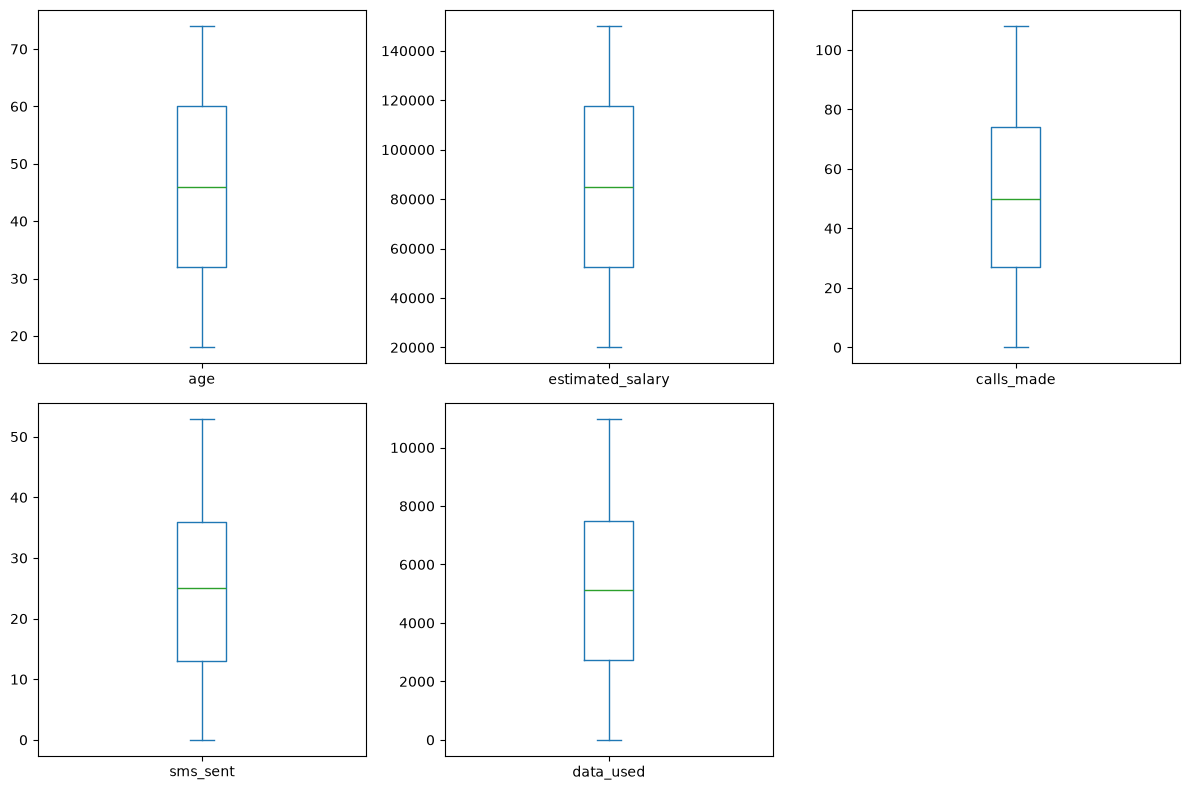

In [14]:
# outliers
num_cols = ["age", "estimated_salary", "calls_made", "sms_sent", "data_used"]

df[num_cols].plot(kind="box", subplots=True, layout=(2, 3), figsize=(12, 8))
plt.tight_layout() 
plt.show()

### Observations
- There are no duplicate rows and no null values.
- `date_of_registration` was converted to a date type.
- Negative values were found in `calls_made` (6,713), `sms_sent` (7,375) and `data_used` (6,050). They were replaced with the median of valid values.
- `pincode` was dropped. `customer_id` is kept for the final CHURN-FLAG file.
- The box plots show no outliers in `age`, `estimated_salary`, `calls_made`, `sms_sent` and `data_used`, so no outlier treatment is needed.

# Exploratory Data Analysis(EDA)

Compare churn across the features with charts and numbers, to find which variables influence customers to leave (goal 1).

### Churn rate by category

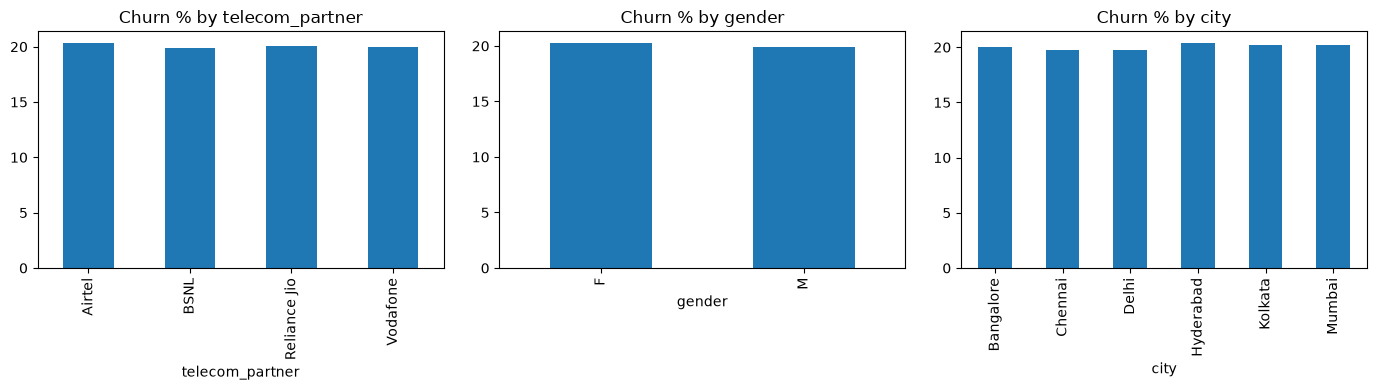

In [15]:
cat_cols = ["telecom_partner", "gender", "city"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, cat_cols):
    # churn percentage in each category
    (df.groupby(col)["churn"].mean() * 100).plot(kind="bar", ax=ax)
    ax.set_title(f"Churn % by {col}")
plt.tight_layout()
plt.show()

### Churn rate by state

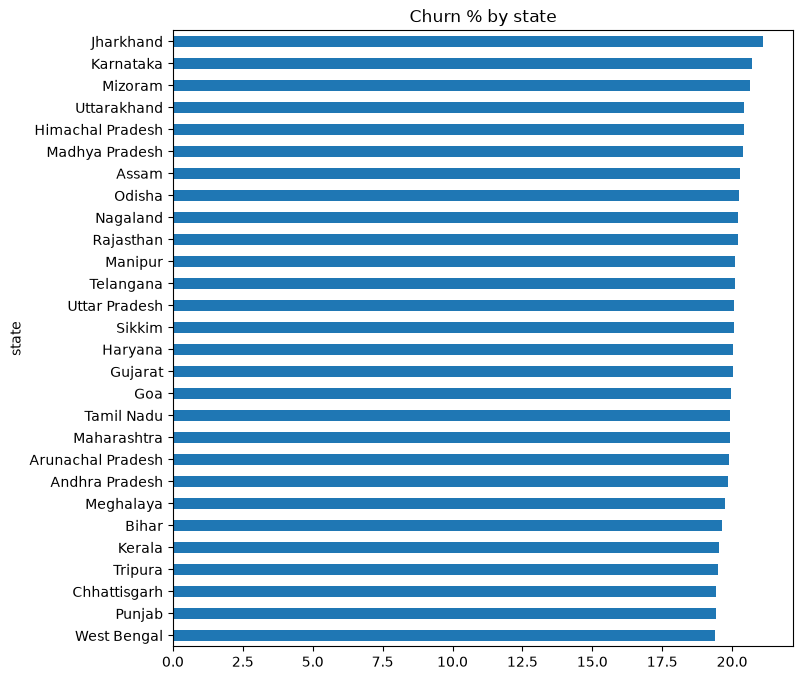

In [16]:
(df.groupby("state")["churn"].mean() * 100).sort_values().plot(kind="barh", figsize=(8, 8))
plt.title("Churn % by state")
plt.show()

### Numeric columns by churn

In [17]:
# Average of each numeric column for churn 0 and 1
df.groupby("churn")[["age", "num_dependents", "estimated_salary", "calls_made", "sms_sent", "data_used" ]].mean()

,age,num_dependents,estimated_salary,calls_made,sms_sent,data_used
churn,,,,,,
0,46.070699,1.999302,85083.726934,50.468160,24.787979,5126.141655
1,46.105167,1.990313,84771.527495,50.618305,24.712147,5137.106642


### Registration date range

In [18]:
print(df["date_of_registration"].min())
print(df["date_of_registration"].max())

2020-01-01 00:00:00
2023-05-04 00:00:00


### Correlation heatmap

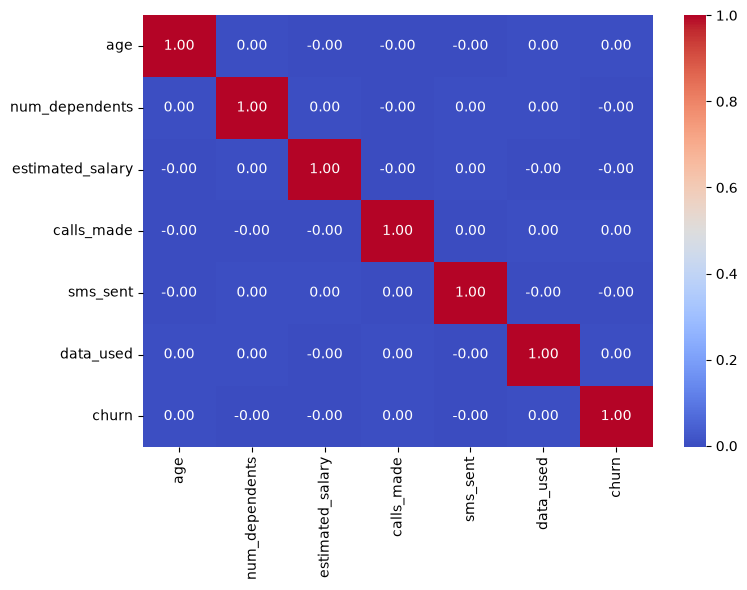

In [19]:
num_df = df.select_dtypes(include="number").drop(columns=["customer_id"])

plt.figure(figsize=(8, 6))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.tight_layout()
plt.show()


### Observations
- Churn is about 20% in every telecom partner, both genders and all 6 cities, so none of them separates churners from non-churners.
- Churn by state ranges only from about 19.4% (West Bengal) to 21.1% (Jharkhand), a very small gap.
- The average of every numeric column is almost the same for churned and non-churned customers (age is about 46, salary about 85,000).
- The correlation heatmap shows all values close to 0.00, so no numeric feature is linearly related to churn.
- Registration dates run from 2020-01-01 to 2023-05-04, so tenure can be created from them.
- No single feature clearly drives churn. Tenure is checked in the extra check section after preprocessing.

# Preprocessing

Convert the data into a numeric form, scale it and split it into train and test sets, because models cannot work with text and raw values.

### Create tenure

In [20]:
# Days since registration, counted up to the latest date in the data
latest = df["date_of_registration"].max()
df["tenure_days"] = (latest - df["date_of_registration"]).dt.days

### Select feature and target

In [21]:
# customer_id and the date column are not used for training
X = df.drop(columns=["churn", "customer_id", "date_of_registration"])
y = df["churn"]

### Encode categorical columns

In [22]:
X["gender"] = X["gender"].map({"F": 0, "M": 1})
X = pd.get_dummies(X, columns=["telecom_partner", "city", "state"], drop_first=True)

### Train-test split

In [23]:
# stratify keeps the same churn ratio in both sets
X_train, X_test, y_train, y_test, = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

### Scale numeric columns

In [24]:
num_cols = ["age", "num_dependents", "estimated_salary", "calls_made", "sms_sent", "data_used", "tenure_days"]

# Scaler is fitted on train data only
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

### Check the shape

In [25]:
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True) * 100)

(194842, 43) (48711, 43)
churn
0    79.951961
1    20.048039
Name: proportion, dtype: float64


### Observations
- A `tenure_days` feature was created from the registration date.
- `customer_id` and the registration date were left out of the features.
- `gender` was encoded as 0 and 1. `telecom_partner`, `city` and `state` were one-hot encoded, which gives 43 feature columns.
- The data was split 80/20: 194,842 rows for training and 48,711 for testing.
- The churn ratio is the same in both sets (about 80% stayed and 20% left).
- Numeric columns were scaled, with the scaler fitted on training data only.
- The class imbalance will be handled with class weights during model building.

# Model building

The EDA showed no single feature clearly explains churn, so machine learning models are used to find patterns across all features together. Four models are trained, from simple to advanced, so they can be compared in the next phase and the best one used for the churn risk score and the CHURN-FLAG.

### Logistic Regression

In [26]:
# Baseline model, class_weight, handles the 80/20 imbalance
lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)
lr_prob = lr.predict_proba(X_test)[:, 1]  # churn probability

print("Train accuracy:", lr.score(X_train, y_train))
print("Test accuracy:", lr.score(X_test, y_test))

Train accuracy: 0.5067131316656573
Test accuracy: 0.5041571718913592


### Decision Tree

In [27]:
# max_depth limits the tree to avoid overfitting
dt = DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42)
dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)
dt_prob = dt.predict_proba(X_test)[:, 1]

print("Train accuracy:", dt.score(X_train, y_train))
print("Test accuracy:", dt.score(X_test, y_test))

Train accuracy: 0.28972192853696843
Test accuracy: 0.28326250744185094


### Random Forest

In [28]:
# Many trees combined give a more stable result
rf = RandomForestClassifier(n_estimators=100, max_depth=8, class_weight="balanced", random_state=42)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

print("Train accuracy:", rf.score(X_train, y_train))
print("Test accuracy:", rf.score(X_test, y_test))

Train accuracy: 0.5786586054341466
Test accuracy: 0.5084272546242122


### XGBoost

In [29]:
# scale_pos_weight = stayed / left, about 80/20
weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1, scale_pos_weight=weight, random_state=42)
xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)
xgb_prob = xgb.predict_proba(X_test)[:, 1]

print("Train accuracy:", xgb.score(X_train, y_train))
print("Test accuracy:", xgb.score(X_test, y_test))

Train accuracy: 0.53206187577627
Test accuracy: 0.49845004208495003


### Observations
- All four models were trained with the class imbalance handled by class weights.
- Test accuracy is low for every model: Logistic Regression 50.4%, Decision Tree 28.3%, Random Forest 50.8% and XGBoost 49.8%.
- These scores are below 80%, which is what predicting "stayed" for everyone would give. The weights make the models predict churn more often, so accuracy is not the right measure here.
- Random Forest has the biggest gap between train (57.9%) and test (50.8%), which shows some overfitting.
- The weak scores match the EDA, where no feature clearly separated churners from non-churners.
- Recall, F1 and ROC-AUC in the next phase will show which model is actually best.

# Model evaluation and comparison

Compare the models on recall, precision, F1 and ROC-AUC, and pick the best one for finding customers who are likely to leave.

### Comparison Table

In [30]:
# Calculates all scores for one model
def get_scores(name, pred, prob):
    return[
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred),
        roc_auc_score(y_test, prob), # uses probabilities, not predictions
    ]

columns = ["Model", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

results = pd.DataFrame([
    get_scores("Logistic Regression", lr_pred, lr_prob),
    get_scores("Decision Tree", dt_pred, dt_prob),
    get_scores("Random Forest", rf_pred, rf_prob),
    get_scores("XGBoost", xgb_pred, xgb_prob),
], columns=columns)

results.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.504,0.201,0.497,0.287,0.506
1,Decision Tree,0.283,0.200,0.858,0.324,0.500
2,Random Forest,0.508,0.199,0.478,0.281,0.499
3,XGBoost,0.498,0.201,0.505,0.288,0.500


### Classification report of the best model

In [31]:
# Logistic Regression has the best ROC-AUC
print(classification_report(y_test, lr_pred))

              precision    recall  f1-score   support

           0       0.80      0.51      0.62     38946
           1       0.20      0.50      0.29      9765

    accuracy                           0.50     48711
   macro avg       0.50      0.50      0.45     48711
weighted avg       0.68      0.50      0.55     48711



### ROC curve

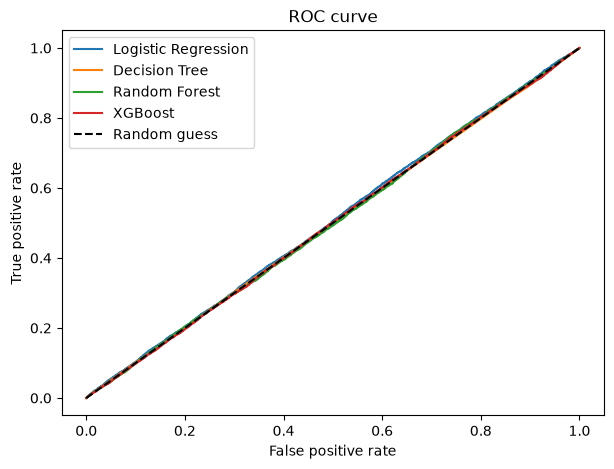

In [32]:
plt.figure(figsize=(7, 5))

for name, prob in [("Logistic Regression", lr_prob), ("Decision Tree", dt_prob),
                   ("Random Forest", rf_prob), ("XGBoost", xgb_prob)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], "k--", label='Random guess')
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")
plt.legend()
plt.show()

### Observations
- ROC-AUC is about 0.50 for all four models (0.506 for Logistic Regression, 0.500 for Decision Tree and XGBoost, 0.499 for Random Forest). This is the same as random guessing.
- The ROC curves of all models lie on the diagonal random-guess line, so no model can separate churners from non-churners.
- Precision for churn is about 0.20 in every model, which is the same as the churn rate in the data (20%). The models add no value over picking customers at random.
- Decision Tree shows the highest recall (0.858) and F1 (0.324), but only because it predicts churn for almost everyone (accuracy 0.283). This is not a real improvement.
- Logistic Regression is marginally the best by ROC-AUC (0.506), so it is used for the classification report.
- The result matches the EDA, where no feature showed a clear link with churn. The data has very little signal, so tuning the models is unlikely to help.

# Extra check: tenure

### Churn % by registration year

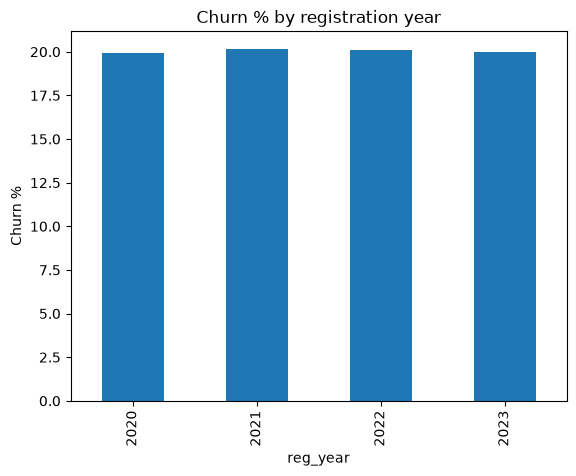

In [33]:
# Churn percentage for customers registered in each year
df["reg_year"] = df["date_of_registration"].dt.year
(df.groupby("reg_year")["churn"].mean() * 100).plot(kind="bar")
plt.title("Churn % by registration year")
plt.ylabel("Churn %")
plt.show()

### Average tenure by churn

In [34]:
# Average tenure for churn 0 and 1
df.groupby("churn")["tenure_days"].mean()

churn
0    610.290875
1    608.839945
Name: tenure_days, dtype: float64

### Drop the helper column

In [35]:
# reg_year is only for this check
df = df.drop(columns=["reg_year"])

### Observations
- Churn is about 20% in every registration year (2020 to 2023), so registration year does not affect churn.
- Average tenure is almost the same for both groups: 610 days for customers who stayed and 609 days for customers who left.
- Tenure carries no signal either, which matches the rest of the EDA.

# Feature importance
Check which features the best model relies on most, which gives the final answer to goal 1.

### Get the importance of each feature

In [36]:
# Importance score of every feature, highest first
importance = pd.Series(rf.feature_importances_, index=X_train.columns)
importance = importance.sort_values(ascending=False)

importance.head(10)

estimated_salary                0.146822
data_used                       0.134414
tenure_days                     0.128691
calls_made                      0.118250
sms_sent                        0.097577
age                             0.093007
num_dependents                  0.040544
gender                          0.016596
telecom_partner_Reliance Jio    0.014600
telecom_partner_BSNL            0.013262
dtype: float64

### Plot the top 10 features

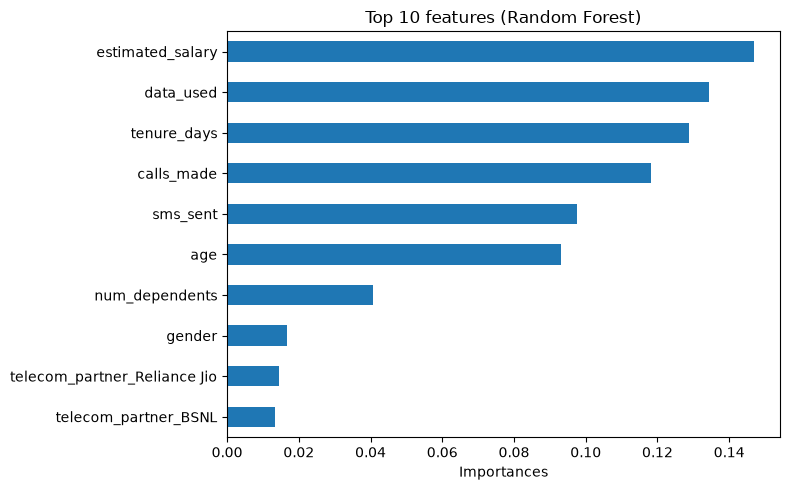

In [37]:
plt.figure(figsize=(8, 5))

# [::-1] puts the most important feature at the top
importance.head(10)[::-1].plot(kind="barh")

plt.title("Top 10 features (Random Forest)")
plt.xlabel("Importances")
plt.tight_layout()
plt.show()

### Importance of the original columns

In [38]:
# State, city and partner are split into many columns by encoding, so they are grouped back
groups = {
    "state": importance[importance.index.str.startswith("state_")].sum(),
    "city": importance[importance.index.str.startswith("city_")].sum(),
    "telecom_partner": importance[importance.index.str.startswith("telecom_partner_")].sum(),
}

# Remaining columns keep their own scores
others = importance[~importance.index.str.startswith(("state_", "city_", "telecom_partner_"))]

grouped = pd.concat([others, pd.Series(groups)]).sort_values(ascending=False)
grouped

estimated_salary    0.146822
data_used           0.134414
state               0.128697
tenure_days         0.128691
calls_made          0.118250
sms_sent            0.097577
age                 0.093007
city                0.055992
num_dependents      0.040544
telecom_partner     0.039412
gender              0.016596
dtype: float64

### Observations
- Random Forest gives the most importance to `estimated_salary` (0.147), `data_used` (0.134) and `tenure_days` (0.129), followed closely by `state` (0.129) and `calls_made` (0.118).
- `gender` (0.017), `telecom_partner` (0.039) and `num_dependents` (0.041) are the least important.
- The scores are small and close together, with no feature standing out clearly.
- Numeric columns get higher scores because a forest has many split points to try on them. With a model close to random guessing, these scores mostly reflect that and not a real link with churn.
- This matches the EDA, where churn was about 20% in every group and all correlations were near 0. No variable can be named as a clear driver of churn.

# Churn risk score
Turn the model's churn probability into a score and Low, Medium and High bands, so retention campaigns can focus on the riskiest customers (goal 2).

### Score every customer

In [39]:
# Scaled train and test rows put back together in the original order
X_all = pd.concat([X_train, X_test]).sort_index()

# Churn probability for every customer, as a score from 0 to 100
df["churn_risk_score"] = (rf.predict_proba(X_all)[:, 1] * 100).round(1)

### Create risk bands

In [40]:
# Customers split into three equal groups by score
df["risk_band"] = pd.qcut(df["churn_risk_score"], q=3, labels=["Low", "Medium", "High"])

### Customers in each band

In [41]:
df["risk_band"].value_counts()

risk_band
Low       86413
Medium    80867
High      76273
Name: count, dtype: int64

### Actual churn rate in each band

In [42]:
# A useful score should show a higher churn % in the High band
(df.groupby("risk_band")["churn"].mean() * 100).round(1)

risk_band
Low       12.5
Medium    20.2
High      28.5
Name: churn, dtype: float64

### Churn rate by band on test customers only

In [43]:
# Test customers were not seen by the model during training
test_df = df.loc[X_test.index]
(test_df.groupby("risk_band")["churn"].mean() * 100).round(1)

risk_band
Low       20.2
Medium    20.1
High      19.9
Name: churn, dtype: float64

### Observations
- Every customer got a churn risk score from 0 to 100, based on the Random Forest probability, and was placed in a Low, Medium or High band.
- The bands hold 86,413 (Low), 80,867 (Medium) and 76,273 (High) customers. They are not exactly equal because many customers share the same score.
- Across all customers, churn looks like it rises from 12.5% (Low) to 28.5% (High), but this includes customers the model was trained on, so it is overstated.
- On test customers only, churn is 20.2% (Low), 20.1% (Medium) and 19.9% (High). The High band is not riskier than the Low band, so the score cannot separate risky customers from safe ones.
- This matches the ROC-AUC of about 0.50 and the EDA, where no feature was linked with churn.

# CHURN-FLAG
Mark each customer as YES (1) or NO (0), so email campaigns with offers can target the YES customers (goal 3).

### Create the flag

In [44]:
# Customers in the High risk band get YES (1), the rest get NO (0)
df["churn_flag"] = (df["risk_band"] == "High").astype(int)

### Check the flag

In [45]:
df["churn_flag"].value_counts()

churn_flag
0    167280
1     76273
Name: count, dtype: int64

### Compare the flag with actual churn

In [46]:
# Rows are actual churn, columns are the flag
pd.crosstab(df["churn"], df["churn_flag"])

churn_flag,0,1
churn,,
0,140179,54547
1,27101,21726


### Save the final file

In [47]:
# Only the columns needed for the campaign team
final = df[["customer_id", "churn_risk_score", "risk_band", "churn_flag"]]
final.to_csv("churn_flag_customers.csv", index=False)

### Observations
- The CHURN-FLAG was created from the risk score: customers in the High band get YES (1) and the rest get NO (0).
- 76,273 customers (31%) are flagged YES and 167,280 are flagged NO.
- Of the 76,273 flagged customers, 21,726 actually churned (28.5%) and 54,547 did not.
- The flag catches 21,726 of the 48,827 customers who left (44.5%) and misses 27,101 of them.
- These numbers include customers the model was trained on, so they look better than they are. On test customers, the High band churn is only 19.9%, which is not higher than the overall churn rate of 20%.
- So the flag works no better than picking customers at random, and about 7 in 10 flagged customers would not have left.
- The final file with `customer_id`, risk score, risk band and CHURN-FLAG was saved as a CSV for the campaign team.

# Business suggestions and challenges
Explain how No-Churn Telecom can use the results, and note the problems faced during the project.

### Business suggestions

| Suggestion | Why |
|---|---|
| Collect richer data | The current data shows no link with churn. Complaints, billing details, contract type, plan price and customer care calls would give the model something to learn from. |
| Use the risk score and CHURN-FLAG as a pilot only | The process works (score, bands, flag, file), but the flag is no better than random selection. Real offers should wait for a stronger model. |
| Test before spending | Send the offer email to a small flagged group and a small unflagged group, then compare the churn. This shows if the flag helps before the full campaign. |
| Prepare customer care | Once a reliable flag exists, flagged customers can get priority tickets and faster resolution. |

### Challenges

| Challenge | What happened | How it was handled |
|---|---|---|
| No clear drivers | Churn was about 20% in every partner, gender, city, state and registration year, and all correlations were near 0. | Reported honestly, as no feature clearly drives churn. |
| Invalid values | `calls_made`, `sms_sent` and `data_used` had negative values. | Replaced with the median of valid values. |
| Class imbalance | Only 20% of customers churned. | Class weights were used, and accuracy was not trusted. |
| Weak models | All four models gave a ROC-AUC of about 0.50. | Recall, F1 and ROC-AUC were used to compare, and the weak result was reported. |
| Inflated risk score | On all customers the bands looked useful, but on test customers churn was almost the same (20.2%, 20.1% and 19.9%). | Checked on test customers only. |